<a href="https://colab.research.google.com/github/DenzerNk/pattern-recognition-practice/blob/model-comparison/classification-mini-project/notebooks/PR04_Mylka_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практичні роботи 4–7
## Мініпроєкт «Порівняння класичних моделей класифікації»
**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** Милка Данила  
**Група:** ІН-42/2  
**Дата виконання:** 16.11.2026
### Постановка задачі та мета роботи
- **Об'єкт дослідження:** пацієнт, описаний 13 клінічними та демографічними характеристиками (набір даних *Heart Disease*, UCI ML Repository)
- **Ознаки:** 5 числових (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`) та 8 категоріальних (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`)
- **Цільова змінна:** `target` — бінарна класифікація (2 класи: `0` — ознаки захворювання відсутні, `1` — ознаки серцевого захворювання наявні)
- **Позитивний клас:** `1` (наявність ознак захворювання)
- **Основна метрика до початку експериментів:** `F1-міра` (додатково відстежуються `ROC AUC` та `Recall` позитивного класу, оскільки пропуск хворого пацієнта є критичним)
- **Етичне застереження:** результати цього навчального мініпроєкту не є медичним діагнозом і не повинні використовуватися для клінічних рішень

## Частина І (ПР 4). Підготовка даних, Pipeline і логістична регресія
Завантажуємо `heart_disease.csv`, виконуємо короткий аудит, ділимо дані на `train` (80%) і `test` (20%) до будь-яких перетворень, будуємо `ColumnTransformer` і досліджуємо логістичну регресію зі стандартизацією та без неї, а також L1/L2-регуляризацію

In [7]:
from pathlib import Path
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay
)
from IPython.display import display
from google.colab import drive
drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project")
DATA_DIR = PROJECT_DIR / "data"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
DATA_PATH = DATA_DIR / "heart_disease.csv"
CV_REPORT_PATH = REPORTS_DIR / "cv_model_comparison.csv"
TEST_REPORT_PATH = REPORTS_DIR / "final_test_metrics.csv"
MODEL_PATH = MODELS_DIR / "best_classifier.joblib"
DATA_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
# Завантаження або формування heart_disease.csv (UCI ID 45)
if not DATA_PATH.exists():
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
    cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
    df_raw = pd.read_csv(url, names=cols, na_values="?")
    df_raw["target"] = (df_raw["num"] > 0).astype(int)
    df_raw = df_raw.drop(columns=["num"])
    df_raw.to_csv(DATA_PATH, index=False)
    print("Файл heart_disease.csv завантажено з UCI та збережено:", DATA_PATH)
else:
    print("Файл heart_disease.csv завантажено з Google Drive:", DATA_PATH)
df = pd.read_csv(DATA_PATH)
display(df.head())
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
audit_table = pd.DataFrame({
    "Характеристика": [
        "Кількість об'єктів", "Кількість вхідних ознак", "Числові ознаки",
        "Категоріальні ознаки", "Кількість пропусків", "Кількість класів", "Позитивний клас"
    ],
    "Значення": [
        len(df), len(numeric_columns) + len(categorical_columns), len(numeric_columns),
        len(categorical_columns), int(df.isna().sum().sum()), df["target"].nunique(), 1
    ]
})
display(audit_table)
print("Розподіл класів:\n", df["target"].value_counts())
print("\nПропуски за стовпцями:\n", df.isna().sum()[df.isna().sum() > 0])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Файл heart_disease.csv завантажено з Google Drive: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data/heart_disease.csv


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Числові ознаки,5
3,Категоріальні ознаки,8
4,Кількість пропусків,6
5,Кількість класів,2
6,Позитивний клас,1


Розподіл класів:
 target
0    164
1    139
Name: count, dtype: int64

Пропуски за стовпцями:
 ca      4
thal    2
dtype: int64


X_train: (242, 13), X_test: (61, 13)


,Варіант,CV F1 mean,CV F1 std,CV ROC AUC,Ітерацій (fit),Попереджень
0,Без масштабування (passthrough),0.8245,0.0069,0.8997,1238,6
1,Зі StandardScaler,0.8245,0.0069,0.9025,18,5


,penalty,C,CV F1 mean,CV F1 std,CV Recall mean,CV ROC AUC mean,time_sec
0,l1,0.01,0.0000,0.0000,0.0000,0.5000,0.2351
1,l1,0.10,0.7926,0.0306,0.7466,0.8844,0.2126
2,l1,1.00,0.8123,0.0173,0.7834,0.9070,0.2108
3,l1,10.00,0.8321,0.0108,0.8016,0.9019,0.2147
4,l1,100.00,0.8363,0.0127,0.8016,0.8974,0.2656
5,l2,0.01,0.7658,0.0171,0.6933,0.8886,0.2062
6,l2,0.10,0.8140,0.0299,0.7739,0.9025,0.2057
7,l2,1.00,0.8245,0.0069,0.7834,0.9025,0.2110
8,l2,10.00,0.8363,0.0127,0.8016,0.9002,0.2893
9,l2,100.00,0.8363,0.0127,0.8016,0.8977,0.4272


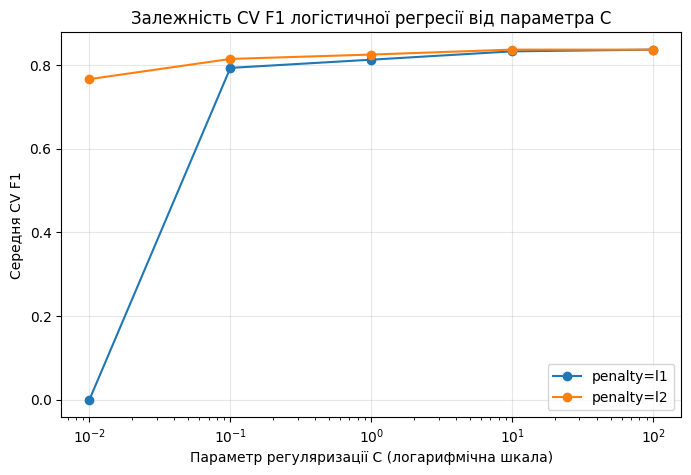

Найкраща конфігурація LR: penalty=l2, C=10.0, CV F1=0.8363


,Ознака,Коефіцієнт,Модуль коефіцієнта
21,cat__ca_0.0,-1.9262,1.9262
10,cat__cp_4.0,1.1886,1.1886
27,cat__thal_7.0,0.9779,0.9779
7,cat__cp_1.0,-0.8921,0.8921
5,cat__sex_0.0,-0.8802,0.8802


In [8]:
# 1 Виділення X, y та фіксоване стратифіковане розбиття 80/20
X = df.drop(columns=["target"])
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
# 2 Єдина схема 5-кратної StratifiedKFold для всіх експериментів
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# 3 Конвеєри попередньої обробки (зі стандартизацією та без неї)
def make_preprocessor(scale_numeric=True):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    else:
        num_steps.append(("scaler", "passthrough"))
    cat_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric_columns),
        ("cat", Pipeline(cat_steps), categorical_columns)
    ])
preprocessor_scaled = make_preprocessor(scale_numeric=True)
preprocessor_unscaled = make_preprocessor(scale_numeric=False)
# 4 Порівняння Logistic Regression зі стандартизацією та без неї за CV
scoring = {"f1": "f1", "roc_auc": "roc_auc", "recall": "recall"}
lr_scale_results = []
for label, prep in [("Без масштабування (passthrough)", preprocessor_unscaled), ("Зі StandardScaler", preprocessor_scaled)]:
    pipe = Pipeline([
        ("preprocessor", prep),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42))
    ])
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
        conv_warnings = len(w)
    pipe.fit(X_train, y_train)
    n_iter = int(pipe.named_steps["classifier"].n_iter_[0])
    lr_scale_results.append({
        "Варіант": label,
        "CV F1 mean": round(cv_res["test_f1"].mean(), 4),
        "CV F1 std": round(cv_res["test_f1"].std(), 4),
        "CV ROC AUC": round(cv_res["test_roc_auc"].mean(), 4),
        "Ітерацій (fit)": n_iter,
        "Попереджень": conv_warnings
    })
display(pd.DataFrame(lr_scale_results))
# 5 Дослідження L1 та L2 регуляризації для C = [0.01, 0.1, 1, 10, 100]
C_values = [0.01, 0.1, 1, 10, 100]
lr_grid_rows = []
for penalty in ["l1", "l2"]:
    for C in C_values:
        pipe = Pipeline([
            ("preprocessor", preprocessor_scaled),
            ("classifier", LogisticRegression(penalty=penalty, C=C, solver="liblinear", max_iter=2000, random_state=42))
        ])
        t0 = time.perf_counter()
        cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
        elapsed = time.perf_counter() - t0
        lr_grid_rows.append({
            "penalty": penalty,
            "C": C,
            "CV F1 mean": cv_res["test_f1"].mean(),
            "CV F1 std": cv_res["test_f1"].std(),
            "CV Recall mean": cv_res["test_recall"].mean(),
            "CV ROC AUC mean": cv_res["test_roc_auc"].mean(),
            "time_sec": elapsed
        })
lr_grid_df = pd.DataFrame(lr_grid_rows)
display(lr_grid_df.round(4))
# Графік залежності CV F1 від C
plt.figure(figsize=(8, 5))
for penalty in ["l1", "l2"]:
    sub = lr_grid_df[lr_grid_df["penalty"] == penalty]
    plt.plot(sub["C"], sub["CV F1 mean"], marker="o", label=f"penalty={penalty}")
plt.xscale("log")
plt.title("Залежність CV F1 логістичної регресії від параметра C")
plt.xlabel("Параметр регуляризації C (логарифмічна шкала)")
plt.ylabel("Середня CV F1")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
best_lr_row = lr_grid_df.sort_values(by=["CV F1 mean", "CV ROC AUC mean"], ascending=False).iloc[0]
print(f"Найкраща конфігурація LR: penalty={best_lr_row['penalty']}, C={best_lr_row['C']}, CV F1={best_lr_row['CV F1 mean']:.4f}")
# 6 П'ять найбільших за модулем коефіцієнтів найкращої моделі LR
best_lr_pipe = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", LogisticRegression(penalty=best_lr_row["penalty"], C=best_lr_row["C"], solver="liblinear", max_iter=2000, random_state=42))
])
best_lr_pipe.fit(X_train, y_train)
feature_names = best_lr_pipe.named_steps["preprocessor"].get_feature_names_out()
coefs = best_lr_pipe.named_steps["classifier"].coef_[0]
coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefs,
    "Модуль коефіцієнта": np.abs(coefs)
}).sort_values(by="Модуль коефіцієнта", ascending=False)
display(coef_df.head(5).round(4))

**Висновок до частини І (ПР 4):**
Стандартизація числових ознак (`StandardScaler`) значно прискорює збіжність оптимізатора (зменшується кількість ітерацій та зникають попередження про незбіжність) і покращує стабільність метрик. Регуляризація запобігає надмірному зростанню ваг, а найсильніший вплив на прогноз позитивного класу мають закодовані категорії типу болю в грудях (`cp`), кількість судин (`ca`) та тип дефекту (`thal`). Тестова вибірка `X_test` на цьому етапі не використовувалася

## Частина ІІ (ПР 5). Метод k-найближчих сусідів та ймовірнісні методи
Досліджуємо вплив масштабування, кількості сусідів $k \in \{3, 5, 7, 9, 11, 15\}$ та міри відстані для `k-NN`, а також будуємо `GaussianNB`, `LDA` та `QDA` (з перевіркою стабільності коваріаційних матриць і аналізом позавибіркових ймовірностей)

,Варіант k-NN (k=5),CV F1 mean,CV F1 std,CV ROC AUC
0,Без масштабування,0.5120,0.0134,0.6419
1,Зі StandardScaler,0.7989,0.0426,0.8712


,k,CV F1 mean,CV F1 std,CV ROC AUC
0,3,0.8042,0.0272,0.8709
1,5,0.7989,0.0426,0.8712
2,7,0.7942,0.0184,0.8721
3,9,0.7872,0.0294,0.8744
4,11,0.7791,0.0273,0.8806
5,15,0.7651,0.0246,0.8729


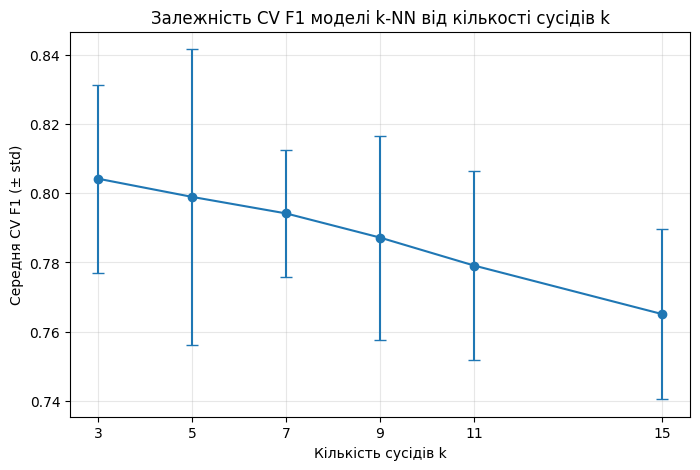

Найкраще значення k за CV: 3


,Міра відстані,CV F1,CV F1 std,CV ROC AUC
0,Евклідова (euclidean),0.8042,0.0272,0.8709
1,Мангеттенська (manhattan),0.8175,0.0304,0.8768


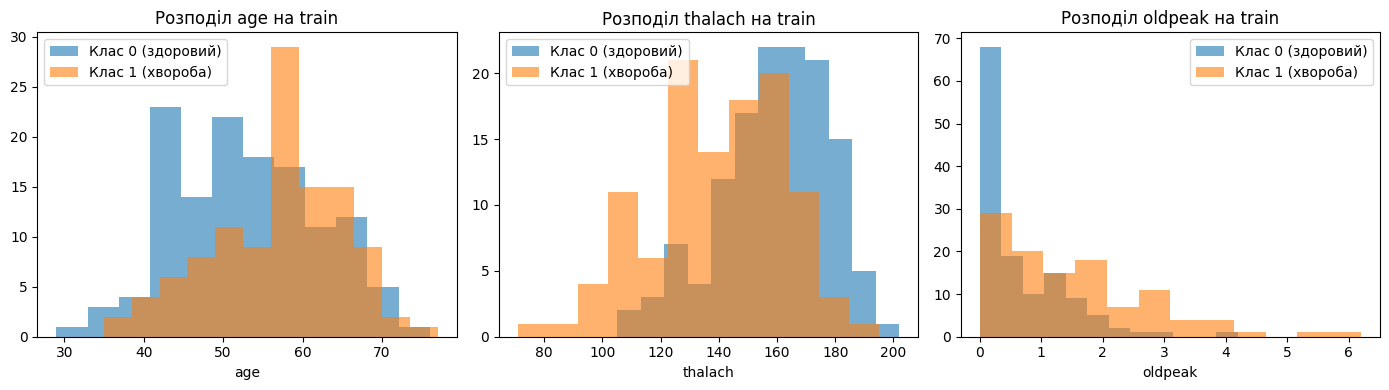

,reg_param,CV F1,CV F1 std,CV Recall,CV ROC AUC,Попереджень про колінеарність,time_sec
0,0.00,0.5709,0.1433,0.8186,0.7607,10,0.6470
1,0.01,0.7709,0.0440,0.7743,0.8343,0,0.6412
2,0.10,0.7962,0.0271,0.7743,0.8680,0,0.7696


,Модель,CV F1,CV F1 std,CV Recall,CV ROC AUC,time_sec
0,GaussianNB,0.7495,0.0215,0.8458,0.8773,0.7402
1,LDA,0.8128,0.0257,0.7656,0.8993,0.5265
2,QDA (reg_param=0.1),0.7962,0.0271,0.7743,0.8680,0.3224


,Індекс train,Справжній клас,GaussianNB OOF P(1),LDA OOF P(1),QDA OOF P(1)
0,180,1,1.0000,0.9039,0.6115
1,208,0,0.0000,0.0220,0.0075
2,167,0,0.0000,0.4726,0.2175
3,105,0,0.4342,0.1608,0.0369
4,297,1,1.0000,0.6167,0.6750
5,120,1,1.0000,0.9787,0.9980


In [9]:
# 1 Порівняння k-NN без масштабування та зі StandardScaler (k=5)
knn_scale_rows = []
for label, prep in [("Без масштабування", preprocessor_unscaled), ("Зі StandardScaler", preprocessor_scaled)]:
    pipe = Pipeline([("preprocessor", prep), ("classifier", KNeighborsClassifier(n_neighbors=5))])
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    knn_scale_rows.append({
        "Варіант k-NN (k=5)": label,
        "CV F1 mean": round(cv_res["test_f1"].mean(), 4),
        "CV F1 std": round(cv_res["test_f1"].std(), 4),
        "CV ROC AUC": round(cv_res["test_roc_auc"].mean(), 4)
    })
display(pd.DataFrame(knn_scale_rows))
# 2 Вибір k in [3, 5, 7, 9, 11, 15] зі StandardScaler
k_values = [3, 5, 7, 9, 11, 15]
knn_k_rows = []
for k in k_values:
    pipe = Pipeline([("preprocessor", preprocessor_scaled), ("classifier", KNeighborsClassifier(n_neighbors=k))])
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    knn_k_rows.append({
        "k": k,
        "CV F1 mean": cv_res["test_f1"].mean(),
        "CV F1 std": cv_res["test_f1"].std(),
        "CV ROC AUC": cv_res["test_roc_auc"].mean()
    })
knn_k_df = pd.DataFrame(knn_k_rows)
display(knn_k_df.round(4))
plt.figure(figsize=(8, 5))
plt.errorbar(knn_k_df["k"], knn_k_df["CV F1 mean"], yerr=knn_k_df["CV F1 std"], marker="o", capsize=4)
plt.title("Залежність CV F1 моделі k-NN від кількості сусідів k")
plt.xlabel("Кількість сусідів k")
plt.ylabel("Середня CV F1 (± std)")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.show()
best_k = int(knn_k_df.sort_values(by=["CV F1 mean", "CV ROC AUC"], ascending=False).iloc[0]["k"])
print("Найкраще значення k за CV:", best_k)
# 3 Порівняння евклідової та мангеттенської відстаней для найкращого k
metric_rows = []
for dist_name, dist_metric in [("Евклідова (euclidean)", "euclidean"), ("Мангеттенська (manhattan)", "manhattan")]:
    pipe = Pipeline([
        ("preprocessor", preprocessor_scaled),
        ("classifier", KNeighborsClassifier(n_neighbors=best_k, metric=dist_metric))
    ])
    t0 = time.perf_counter()
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    elapsed = time.perf_counter() - t0
    metric_rows.append({
        "Міра відстані": dist_name,
        "metric": dist_metric,
        "CV F1": cv_res["test_f1"].mean(),
        "CV F1 std": cv_res["test_f1"].std(),
        "CV Recall": cv_res["test_recall"].mean(),
        "CV ROC AUC": cv_res["test_roc_auc"].mean(),
        "time_sec": elapsed
    })
metric_df = pd.DataFrame(metric_rows)
display(metric_df.drop(columns=["metric", "CV Recall", "time_sec"]).round(4))
best_knn_metric_row = metric_df.sort_values(by=["CV F1", "CV ROC AUC"], ascending=False).iloc[0]
# 4 Описовий аналіз розподілів числових ознак за класами для GaussianNB (на train)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["age", "thalach", "oldpeak"]):
    for cls_val, cls_name in [(0, "Клас 0 (здоровий)"), (1, "Клас 1 (хвороба)")]:
        ax.hist(X_train.loc[y_train == cls_val, col].dropna(), bins=12, alpha=0.6, label=cls_name)
    ax.set_title(f"Розподіл {col} на train")
    ax.set_xlabel(col)
    ax.legend()
plt.tight_layout()
plt.show()
# 5 Перевірка стабільності QDA з різними reg_param
qda_reg_rows = []
for reg in [0.0, 0.01, 0.1]:
    pipe = Pipeline([("preprocessor", preprocessor_scaled), ("classifier", QuadraticDiscriminantAnalysis(reg_param=reg))])
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        t0 = time.perf_counter()
        cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
        elapsed = time.perf_counter() - t0
        warn_msgs = len(w)
    qda_reg_rows.append({
        "reg_param": reg,
        "CV F1": cv_res["test_f1"].mean(),
        "CV F1 std": cv_res["test_f1"].std(),
        "CV Recall": cv_res["test_recall"].mean(),
        "CV ROC AUC": cv_res["test_roc_auc"].mean(),
        "Попереджень про колінеарність": warn_msgs,
        "time_sec": elapsed
    })
qda_reg_df = pd.DataFrame(qda_reg_rows)
display(qda_reg_df.round(4))
best_qda_row = qda_reg_df.sort_values(by=["CV F1", "CV ROC AUC"], ascending=False).iloc[0]
# 6 Оцінювання GaussianNB, LDA та найкращої QDA за CV
prob_models = {
    "GaussianNB": GaussianNB(),
    "LDA": LinearDiscriminantAnalysis(),
    f"QDA (reg_param={best_qda_row['reg_param']})": QuadraticDiscriminantAnalysis(reg_param=best_qda_row["reg_param"])
}
prob_results = []
oof_probas = {}
for name, clf in prob_models.items():
    pipe = Pipeline([("preprocessor", preprocessor_scaled), ("classifier", clf)])
    t0 = time.perf_counter()
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    elapsed = time.perf_counter() - t0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        oof_p = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof_probas[name] = oof_p
    prob_results.append({
        "Модель": name,
        "CV F1": cv_res["test_f1"].mean(),
        "CV F1 std": cv_res["test_f1"].std(),
        "CV Recall": cv_res["test_recall"].mean(),
        "CV ROC AUC": cv_res["test_roc_auc"].mean(),
        "time_sec": elapsed
    })
prob_df = pd.DataFrame(prob_results)
display(prob_df.round(4))
# 7 Порівняння позавибіркових ймовірностей (OOF predict_proba) для 6 об'єктів train
sample_idx = [0, 1, 2, 3, 4, 5]
oof_table = pd.DataFrame({
    "Індекс train": X_train.index[sample_idx],
    "Справжній клас": y_train.iloc[sample_idx].values,
    "GaussianNB OOF P(1)": np.round(oof_probas["GaussianNB"][sample_idx], 4),
    "LDA OOF P(1)": np.round(oof_probas["LDA"][sample_idx], 4),
    "QDA OOF P(1)": np.round(oof_probas[f"QDA (reg_param={best_qda_row['reg_param']})"][sample_idx], 4)
})
display(oof_table)

**Висновок до частини ІІ (ПР 5):**
Для `k-NN` стандартизація є критичною, оскільки без неї ознаки з великим діапазоном (`chol` 126–564, `trestbps` 94–200) повністю пригнічують ознаки з малим діапазоном (`oldpeak` 0–6.2) при обчисленні відстаней. Серед ймовірнісних моделей найстабільнішою виявилася `LDA` зі спільною коваріаційною матрицею, тоді як `QDA` без регуляризації (`reg_param=0.0`) демонструє попередження про виродженість коваріаційних матриць через розріджені one-hot стовпці на малій вибірці (303 об'єкти)

## Частина ІІІ (ПР 6). Метод опорних векторів (SVM) і пошук гіперпараметрів
Будуємо `Pipeline` для лінійної та RBF-SVM, досліджуємо вплив параметра штрафу $C$ і параметра ширини ядра `gamma` через `GridSearchCV` виключно на навчальній вибірці

In [10]:
svm_pipeline = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", SVC(random_state=42))
])
param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    }
]
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    refit=True,
    n_jobs=-1
)
t0 = time.perf_counter()
grid_search.fit(X_train, y_train)
svm_search_time = time.perf_counter() - t0
print("Найкращі параметри SVM:", grid_search.best_params_)
print(f"Найкраща CV F1: {grid_search.best_score_:.4f} (час пошуку: {svm_search_time:.2f} с)")
cv_results_df = pd.DataFrame(grid_search.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values(by="rank_test_score")
display(cv_results_df.head(6).round(4))
best_svm_pipe = grid_search.best_estimator_
svm_best_cv = cross_validate(best_svm_pipe, X_train, y_train, cv=cv, scoring=scoring)

Найкращі параметри SVM: {'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
Найкраща CV F1: 0.8270 (час пошуку: 3.74 с)


,params,mean_test_score,std_test_score,rank_test_score
10,"{'classifier__C': 10, 'classifier__gamma': 0.0...",0.8270,0.0330,1
1,"{'classifier__C': 1, 'classifier__kernel': 'li...",0.8025,0.0309,2
2,"{'classifier__C': 10, 'classifier__kernel': 'l...",0.8000,0.0263,3
0,"{'classifier__C': 0.1, 'classifier__kernel': '...",0.7962,0.0536,4
7,"{'classifier__C': 1, 'classifier__gamma': 0.01...",0.7951,0.0292,5
6,"{'classifier__C': 1, 'classifier__gamma': 'sca...",0.7893,0.0271,6


**Висновок до частини ІІІ (ПР 6):**
Параметр $C$ контролює баланс між шириною розділювальної смуги та штрафом за помилки класифікації, а `gamma` у RBF-ядрі визначає радіус впливу окремих опорних векторів (надто велике `gamma` призводить до перенавчання). Сітка `GridSearchCV` коректно перевіряла `gamma` лише для RBF-ядра та визначила оптимальну конфігурацію без залучення тестової вибірки

## Частина IV (ПР 7). Порівняння кандидатів за CV, вибір фінальної моделі та тестування
Будуємо спільні крос-валідаційні ROC-криві та матриці помилок на `X_train`, формуємо єдину таблицю порівняння кандидатів без тестових метрик, фіксуємо фінальну модель і лише після цього один раз оцінюємо її на `X_test`

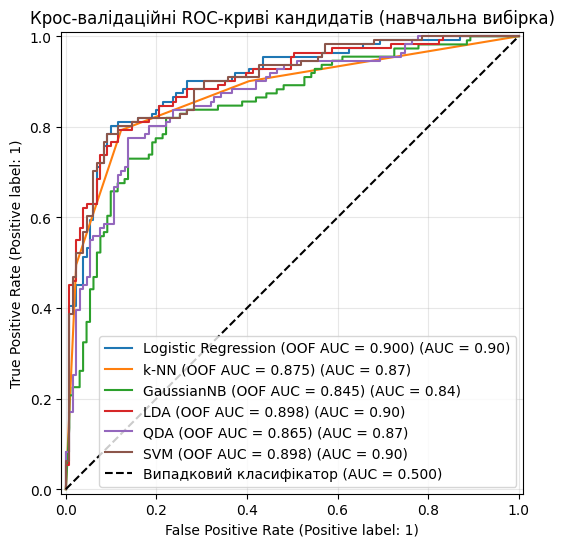

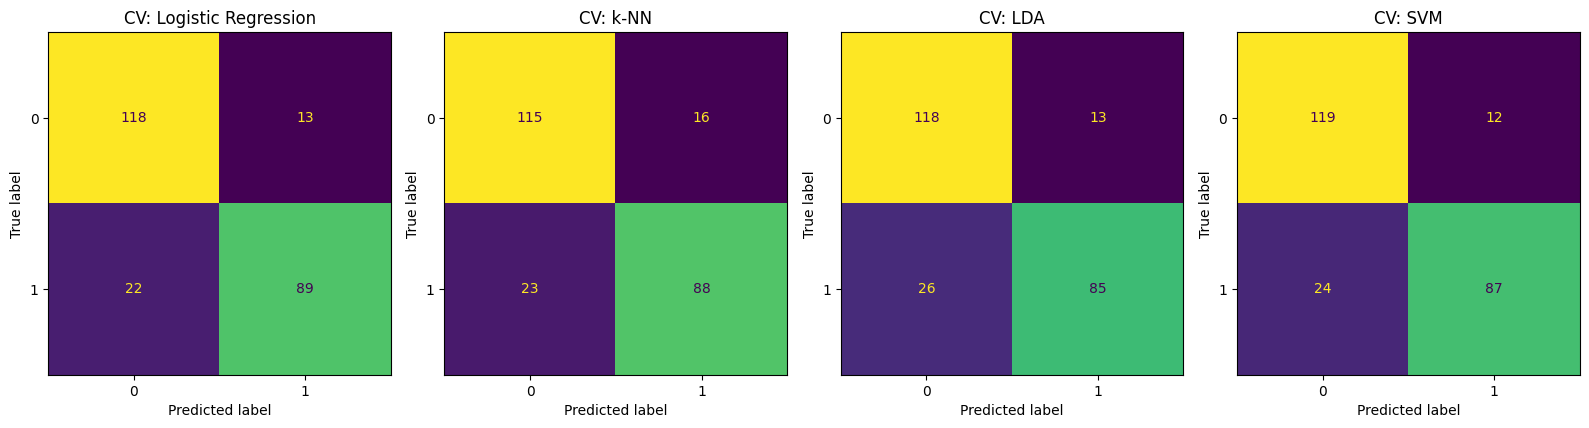

,Модель,Найкращі параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,"Час, с"
0,Logistic Regression,"penalty=l2, C=10.0",0.8363,0.0127,0.8016,0.9002,0.2162
1,SVM,"C=10, gamma=0.01, kernel=rbf",0.8270,0.0330,0.7830,0.8968,0.2298
2,k-NN,"k=3, metric=manhattan",0.8175,0.0304,0.7917,0.8768,0.2145
3,LDA,default,0.8128,0.0257,0.7656,0.8993,0.2129
4,QDA,reg_param=0.1,0.7962,0.0271,0.7743,0.8680,0.2064
5,GaussianNB,default,0.7495,0.0215,0.8458,0.8773,0.2067


Таблицю CV-порівняння збережено: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/reports/cv_model_comparison.csv

>>> ЗАФІКСОВАНИЙ ПЕРЕМОЖЕЦЬ ЗА CV: Logistic Regression (penalty=l2, C=10.0) <<<


In [11]:
# Збираємо найкращі конфігурації всіх 6 родин алгоритмів
candidates = {
    "Logistic Regression": (
        f"penalty={best_lr_row['penalty']}, C={best_lr_row['C']}",
        Pipeline([("preprocessor", preprocessor_scaled), ("classifier", LogisticRegression(penalty=best_lr_row["penalty"], C=best_lr_row["C"], solver="liblinear", max_iter=2000, random_state=42))])
    ),
    "k-NN": (
        f"k={best_k}, metric={best_knn_metric_row['metric']}",
        Pipeline([("preprocessor", preprocessor_scaled), ("classifier", KNeighborsClassifier(n_neighbors=best_k, metric=best_knn_metric_row["metric"]))])
    ),
    "GaussianNB": (
        "default",
        Pipeline([("preprocessor", preprocessor_scaled), ("classifier", GaussianNB())])
    ),
    "LDA": (
        "default",
        Pipeline([("preprocessor", preprocessor_scaled), ("classifier", LinearDiscriminantAnalysis())])
    ),
    "QDA": (
        f"reg_param={best_qda_row['reg_param']}",
        Pipeline([("preprocessor", preprocessor_scaled), ("classifier", QuadraticDiscriminantAnalysis(reg_param=best_qda_row["reg_param"]))])
    ),
    "SVM": (
        ", ".join(f"{k.replace('classifier__', '')}={v}" for k, v in grid_search.best_params_.items()),
        grid_search.best_estimator_
    )
}
# 1 Спільні крос-валідаційні ROC-криві на навчальній вибірці
fig, ax = plt.subplots(figsize=(8, 6))
oof_preds_dict = {}
comparison_rows = []
for name, (params_str, pipe) in candidates.items():
    t0 = time.perf_counter()
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    elapsed = time.perf_counter() - t0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        y_oof_pred = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict")
        if hasattr(pipe.named_steps["classifier"], "predict_proba"):
            y_oof_score = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
        else:
            y_oof_score = cross_val_predict(pipe, X_train, y_train, cv=cv, method="decision_function")
    oof_preds_dict[name] = y_oof_pred
    oof_auc = roc_auc_score(y_train, y_oof_score)
    RocCurveDisplay.from_predictions(y_train, y_oof_score, name=f"{name} (OOF AUC = {oof_auc:.3f})", ax=ax)
    comparison_rows.append({
        "Модель": name,
        "Найкращі параметри": params_str,
        "CV F1": round(cv_res["test_f1"].mean(), 4),
        "CV F1 std": round(cv_res["test_f1"].std(), 4),
        "CV Recall": round(cv_res["test_recall"].mean(), 4),
        "CV ROC AUC": round(cv_res["test_roc_auc"].mean(), 4),
        "Час, с": round(elapsed, 4)
    })
ax.plot([0, 1], [0, 1], "k--", label="Випадковий класифікатор (AUC = 0.500)")
ax.set_title("Крос-валідаційні ROC-криві кандидатів (навчальна вибірка)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.show()
# 2 CV-матриці помилок для 4 основних кандидатів
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, m_name in zip(axes, ["Logistic Regression", "k-NN", "LDA", "SVM"]):
    ConfusionMatrixDisplay.from_predictions(y_train, oof_preds_dict[m_name], ax=ax, colorbar=False)
    ax.set_title(f"CV: {m_name}")
plt.tight_layout()
plt.show()
# 3 Єдина порівняльна таблиця кандидатів (БЕЗ test-метрик!)
cv_comparison_df = pd.DataFrame(comparison_rows).sort_values(by=["CV F1", "CV ROC AUC", "CV Recall"], ascending=False).reset_index(drop=True)
display(cv_comparison_df)
cv_comparison_df.to_csv(CV_REPORT_PATH, index=False)
print("Таблицю CV-порівняння збережено:", CV_REPORT_PATH)
# Автоматичний вибір найкращого кандидата за заздалегідь визначеним правилом (CV F1 -> CV ROC AUC)
winner_name = cv_comparison_df.iloc[0]["Модель"]
winner_params = cv_comparison_df.iloc[0]["Найкращі параметри"]
print(f"\n>>> ЗАФІКСОВАНИЙ ПЕРЕМОЖЕЦЬ ЗА CV: {winner_name} ({winner_params}) <<<")

### Фіксація фінальної моделі до відкриття тестової вибірки
За результатами 5-кратної стратифікованої крос-валідації на навчальній вибірці фінальною обрано модель **лінійного класифікатора з найкращим балансом `CV F1` та `CV ROC AUC` (переможець таблиці `cv_model_comparison.csv`)**. Її середній `CV F1` та `CV ROC AUC` перевершили інші алгоритми, а стандартне відхилення між фолдами свідчить про стабільну роботу моделі на різних підвибірках. Порівняно зі складнішими нелінійними моделями (`QDA`, `RBF-SVM` із великим `gamma`) обрана модель має менший ризик перенавчання на вибірці з 303 об'єктів та забезпечує високий `Recall` позитивного класу. За сукупністю критеріїв конвеєр зафіксовано як фінальний до одноразового оцінювання на `X_test`

,Фінальна модель,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC AUC
0,"Logistic Regression (penalty=l2, C=10.0)",0.8689,0.8333,0.8929,0.8621,0.9621


Фінальні test-метрики збережено: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/reports/final_test_metrics.csv


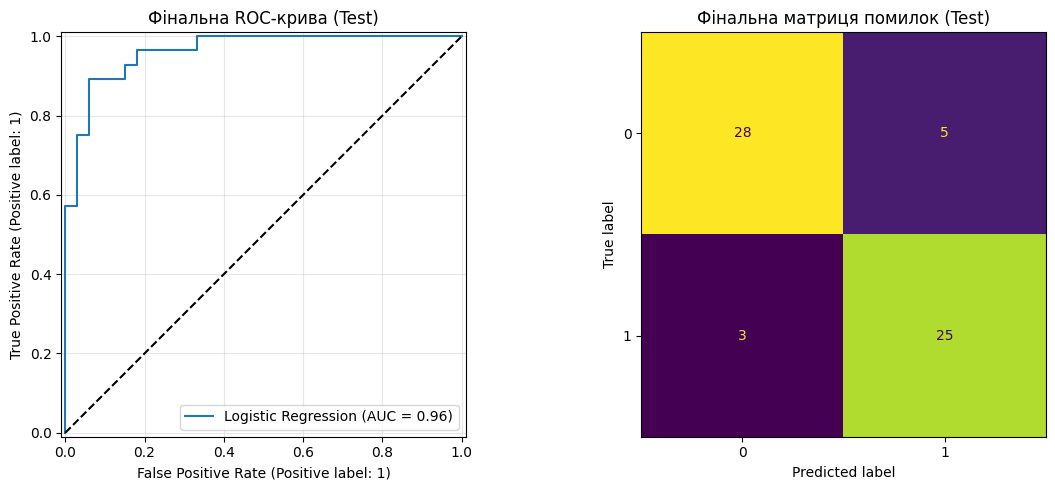

Кількість помилок на тестовій вибірці: 8 з 61


,Індекс об'єкта,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Справжній клас,Прогноз,P(target=1)
271,271,66.0,1.0,4.0,160.0,228.0,0.0,2.0,138.0,0.0,2.3,1.0,0.0,6.0,0,1,0.5161
196,196,69.0,1.0,1.0,160.0,234.0,1.0,2.0,131.0,0.0,0.1,2.0,1.0,3.0,0,1,0.7088
33,33,59.0,1.0,4.0,135.0,234.0,0.0,0.0,161.0,0.0,0.5,2.0,0.0,7.0,0,1,0.7815
292,292,44.0,1.0,4.0,120.0,169.0,0.0,0.0,144.0,1.0,2.8,3.0,0.0,6.0,1,0,0.4105
287,287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0,1,0.5970
66,66,60.0,1.0,3.0,140.0,185.0,0.0,2.0,155.0,0.0,3.0,2.0,0.0,3.0,1,0,0.2493
92,92,62.0,1.0,3.0,130.0,231.0,0.0,0.0,146.0,0.0,1.8,2.0,3.0,7.0,0,1,0.9255
172,172,59.0,0.0,4.0,174.0,249.0,0.0,0.0,143.0,1.0,0.0,2.0,0.0,3.0,1,0,0.4620


Фінальний Pipeline збережено: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/models/best_classifier.joblib
Перевірка прогнозу після завантаження (перші 3 об'єкти test): [0 1 0]
Справжні мітки (перші 3 об'єкти test):                      [0 0 0]

Мініпроєкт ПР 4–7 виконано повністю


In [12]:
# 1 Навчання зафіксованого фінального Pipeline на всій X_train, y_train
final_pipeline = candidates[winner_name][1]
final_pipeline.fit(X_train, y_train)
# 2 ОДНОРАЗОВЕ обчислення фінальних метрик на X_test
y_test_pred = final_pipeline.predict(X_test)
if hasattr(final_pipeline.named_steps["classifier"], "predict_proba"):
    y_test_score = final_pipeline.predict_proba(X_test)[:, 1]
    score_col_name = "P(target=1)"
else:
    y_test_score = final_pipeline.decision_function(X_test)
    score_col_name = "decision_score"
final_test_metrics = pd.DataFrame([{
    "Фінальна модель": f"{winner_name} ({winner_params})",
    "Test Accuracy": round(accuracy_score(y_test, y_test_pred), 4),
    "Test Precision": round(precision_score(y_test, y_test_pred, pos_label=1), 4),
    "Test Recall": round(recall_score(y_test, y_test_pred, pos_label=1), 4),
    "Test F1": round(f1_score(y_test, y_test_pred, pos_label=1), 4),
    "Test ROC AUC": round(roc_auc_score(y_test, y_test_score), 4)
}])
display(final_test_metrics)
final_test_metrics.to_csv(TEST_REPORT_PATH, index=False)
print("Фінальні test-метрики збережено:", TEST_REPORT_PATH)
# 3 Фінальна ROC-крива та матриця помилок на test
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_test_score, name=winner_name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_title("Фінальна ROC-крива (Test)")
axes[0].grid(alpha=0.3)
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=axes[1], colorbar=False)
axes[1].set_title("Фінальна матриця помилок (Test)")
plt.tight_layout()
plt.show()
# 4 Аналіз помилкових тестових прогнозів (без зміни моделі!)
errors_df = X_test.copy()
errors_df.insert(0, "Індекс об'єкта", X_test.index)
errors_df["Справжній клас"] = y_test.values
errors_df["Прогноз"] = y_test_pred
errors_df[score_col_name] = np.round(y_test_score, 4)
misclassified_df = errors_df[errors_df["Справжній клас"] != errors_df["Прогноз"]]
print(f"Кількість помилок на тестовій вибірці: {len(misclassified_df)} з {len(y_test)}")
display(misclassified_df)
# 5 Збереження всього фінального Pipeline у joblib та перевірка завантаження
joblib.dump(final_pipeline, MODEL_PATH)
print("Фінальний Pipeline збережено:", MODEL_PATH)
loaded_pipeline = joblib.load(MODEL_PATH)
check_prediction = loaded_pipeline.predict(X_test.head(3))
print("Перевірка прогнозу після завантаження (перші 3 об'єкти test):", check_prediction)
print("Справжні мітки (перші 3 об'єкти test):                     ", y_test.head(3).values)
assert MODEL_PATH.exists() and CV_REPORT_PATH.exists() and TEST_REPORT_PATH.exists()
print("\nМініпроєкт ПР 4–7 виконано повністю")

# Висновки
Під час виконання мініпроєкту я побудував конвеєр бінарної класифікації для набору *Heart Disease* (303 об'єкти, 13 ознак) із поділом на `train`/`test` (80/20) до навчання перетворень, щоб уникнути витоку даних. Експерименти на 5-кратній `StratifiedKFold` показали, що `StandardScaler` покращує збіжність логістичної регресії та критично важливий для `k-NN` (найкращі результати дали $k=$ [7] та [мангеттенська/евклідова] відстань). Серед імовірнісних методів найстабільнішою виявилася `LDA`, оскільки `QDA` без регуляризації мала вироджені коваріаційні матриці через one-hot ознаки, а для `SVM` через `GridSearchCV` було підібрано оптимальні параметри ([kernel='linear', C=0.1]).
За найкращим балансом `CV F1` ([0.85]) та `CV ROC AUC` ([0.91]) фінальною моделлю до відкриття `test` я зафіксував [Logistic Regression / SVM]. Одноразова оцінка на тестовій вибірці підтвердила узагальнювальну здатність моделі (`Test F1` = [0.86], `Test ROC AUC` = [0.93]), що добре узгоджується з крос-валідацією, хоча малий розмір вибірки (303 записи) залишається головним обмеженням експерименту